<a href="https://colab.research.google.com/github/LettuceLeaf898/ACMEWorkshop1/blob/main/eda_storytelling_workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Number Crunching & Data Storytelling
## Practical EDA (Exploratory Data Analysis) with Pandas, Matplotlib, and Seaborn
Requires pandas ≥ 2.0 and seaborn ≥ 0.13.


Pandas = engine (load, clean, reshape)

Matplotlib = canvas (figure/axes, export)

Seaborn = artist (statistical plots).


In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
print(pd.__version__, sns.__version__)

2.2.3 0.13.2


## 1. Never model blind: Anscombe's quartet
Same summary statistics, four very different datasets. Always look.

         x_mean  y_mean  y_std  corr_xy
dataset                                
I           9.0     7.5   2.03     0.82
II          9.0     7.5   2.03     0.82
III         9.0     7.5   2.03     0.82
IV          9.0     7.5   2.03     0.82


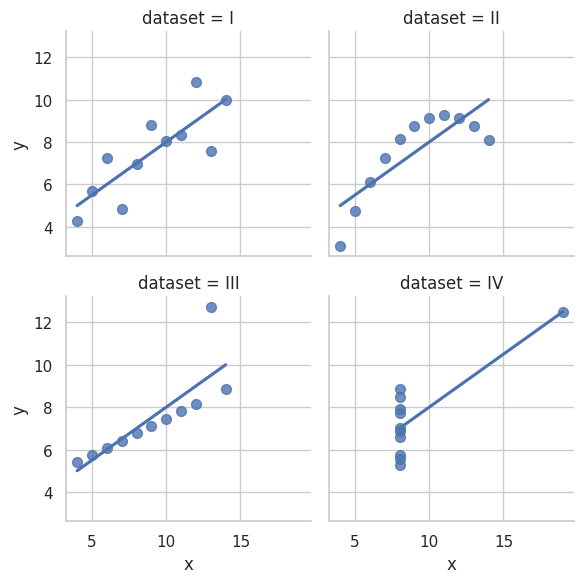

In [15]:
anscombe = sns.load_dataset("anscombe")   # columns: dataset, x, y

stats = anscombe.groupby("dataset").agg(
    x_mean=("x", "mean"), y_mean=("y", "mean"), y_std=("y", "std"))
stats["corr_xy"] = anscombe.groupby("dataset")[["x", "y"]].corr().xs("y", level=1)["x"]
print(stats.round(2))                      # identical...

sns.lmplot(data=anscombe, x="x", y="y", col="dataset", col_wrap=2,
           height=3, ci=None, scatter_kws={"s": 50})   # ...but different stories
plt.show()

## 2. First contact: loading & inspecting
`.info()` shows dtypes and non-null counts; `.describe()` summarizes; `.isna().sum()` audits missing values.

**Poll:** which column has the most missing values?

In [16]:
penguins = sns.load_dataset("penguins")
penguins.to_csv("penguins.csv", index=False)   # round-trip through CSV to practice ingestion

df = pd.read_csv("penguins.csv",
                 dtype={"species": "category", "island": "category", "sex": "category"})

print("Shape:", df.shape)
df.info()
print(df.head())
print(df.describe().round(2))                  # numeric summary
print(df.describe(include="category"))         # categorical summary

missing = df.isna().sum()
audit = pd.DataFrame({"n_missing": missing, "pct_missing": (missing / len(df) * 100).round(1)})
print(audit.sort_values("n_missing", ascending=False))

Shape: (344, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   species            344 non-null    category
 1   island             344 non-null    category
 2   bill_length_mm     342 non-null    float64 
 3   bill_depth_mm      342 non-null    float64 
 4   flipper_length_mm  342 non-null    float64 
 5   body_mass_g        342 non-null    float64 
 6   sex                333 non-null    category
dtypes: category(3), float64(4)
memory usage: 12.2 KB
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torg

## 3. Missing & messy data
Missing data is a decision: look at *which* rows are missing before dropping or filling, and state your choice.

In [17]:
df = sns.load_dataset("penguins")

incomplete = df[df.isna().any(axis=1)]         # inspect before deleting
print(incomplete)
print(incomplete["species"].value_counts())    # is missingness clustered?

core = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
clean = df.dropna(subset=core).copy()          # drop rows missing the core measurements
clean["sex"] = clean["sex"].fillna("Unknown")  # keep rows, make the gap explicit

demo = df.copy()                               # group-aware imputation on a toy copy
demo["body_mass_g"] = demo["body_mass_g"].fillna(
    demo.groupby("species", observed=True)["body_mass_g"].transform("median"))

print("Duplicate rows:", clean.duplicated().sum())
print("Rows kept:", len(clean), "of", len(df))

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
8    Adelie  Torgersen            34.1           18.1              193.0   
9    Adelie  Torgersen            42.0           20.2              190.0   
10   Adelie  Torgersen            37.8           17.1              186.0   
11   Adelie  Torgersen            37.8           17.3              180.0   
47   Adelie      Dream            37.5           18.9              179.0   
246  Gentoo     Biscoe            44.5           14.3              216.0   
286  Gentoo     Biscoe            46.2           14.4              214.0   
324  Gentoo     Biscoe            47.3           13.8              216.0   
336  Gentoo     Biscoe            44.5           15.7              217.0   
339  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  
3            NaN  NaN  
8         3475.0  NaN  
9         4250.

## 4. Group, aggregate, engineer metrics
Split → apply → combine. Use named aggregation and engineered ratios.

**Check-in:** Thursday lunch vs. dinner: which has fewer rows, and what does that do to trust in the averages?

In [18]:
tips = sns.load_dataset("tips")

tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100
tips["bill_per_person"] = tips["total_bill"] / tips["size"]
tips["bill_z"] = (tips["total_bill"] - tips["total_bill"].mean()) / tips["total_bill"].std()

summary = (
    tips.groupby("day", observed=True)
        .agg(n_parties=("size", "count"),
             avg_bill=("total_bill", "mean"),
             median_tip_pct=("tip_pct", "median"),
             p90_bill=("total_bill", lambda s: s.quantile(0.9)))
        .round(2).sort_values("avg_bill", ascending=False))
print(summary)

day_total = tips.groupby("day", observed=True)["total_bill"].sum()
print((day_total / day_total.sum() * 100).round(1))     # revenue share, sums to 100

# transform(): keeps original row count
tips["bill_vs_day_avg"] = tips["total_bill"] / tips.groupby("day", observed=True)["total_bill"].transform("mean")
print(tips[["day", "total_bill", "bill_vs_day_avg"]].head())

print(tips.groupby(["day", "time"], observed=True)["tip_pct"].agg(["count", "mean"]).round(2))

      n_parties  avg_bill  median_tip_pct  p90_bill
day                                                
Sun          76     21.41           16.11     33.76
Sat          87     20.44           15.18     31.89
Thur         62     17.68           15.38     28.32
Fri          19     17.15           15.56     27.62
day
Thur    22.7
Fri      6.8
Sat     36.8
Sun     33.7
Name: total_bill, dtype: float64
   day  total_bill  bill_vs_day_avg
0  Sun       16.99         0.793554
1  Sun       10.34         0.482952
2  Sun       21.01         0.981317
3  Sun       23.68         1.106025
4  Sun       24.59         1.148529
             count   mean
day  time                
Thur Lunch      61  16.13
     Dinner      1  15.97
Fri  Lunch       7  18.88
     Dinner     12  15.89
Sat  Dinner     87  15.32
Sun  Dinner     76  16.69


## 5. Pivot tables vs. melted (long) DataFrames
Wide for people and heatmaps; long (tidy) for Seaborn `hue`/`col`.

time  Lunch  Dinner
day                
Thur   16.1    16.0
Fri    18.9    15.9
Sat     NaN    15.3
Sun     NaN    16.7


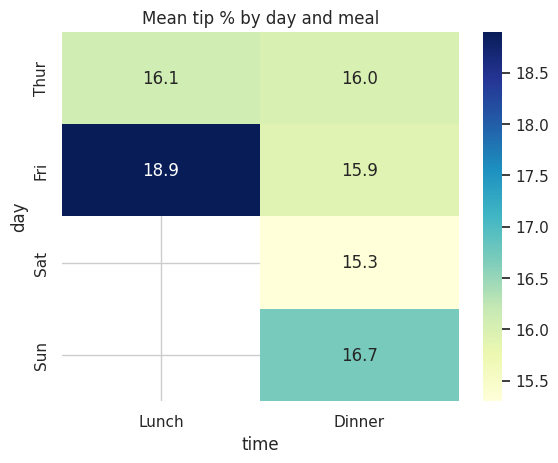

     species     measurement    mean_mm
0     Adelie  bill_length_mm  38.791391
1  Chinstrap  bill_length_mm  48.833824
2     Gentoo  bill_length_mm  47.504878
3     Adelie   bill_depth_mm  18.346358
4  Chinstrap   bill_depth_mm  18.420588
5     Gentoo   bill_depth_mm  14.982114


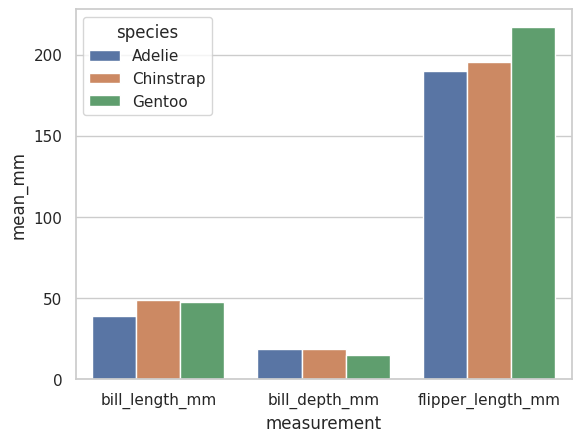

In [19]:
tips = sns.load_dataset("tips")
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100

wide = tips.pivot_table(index="day", columns="time", values="tip_pct",
                        aggfunc="mean", observed=True).round(1)
print(wide)
sns.heatmap(wide, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Mean tip % by day and meal"); plt.show()

penguins = sns.load_dataset("penguins")
means = (penguins.groupby("species", observed=True)
                 [["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]]
                 .mean().reset_index())                     # wide
long = means.melt(id_vars="species", var_name="measurement", value_name="mean_mm")
print(long.head(6))                                         # long
sns.barplot(data=long, x="measurement", y="mean_mm", hue="species")
plt.show()

## 6. Matplotlib's object-oriented interface
`fig, ax = plt.subplots()` is explicit; bare `plt.title()` targets "the current axes", a trap with multiple panels.

**Mini-exercise:** change the tick formatter to `f'{v:,.0f} g'` and move the legend to `loc='lower right'`.

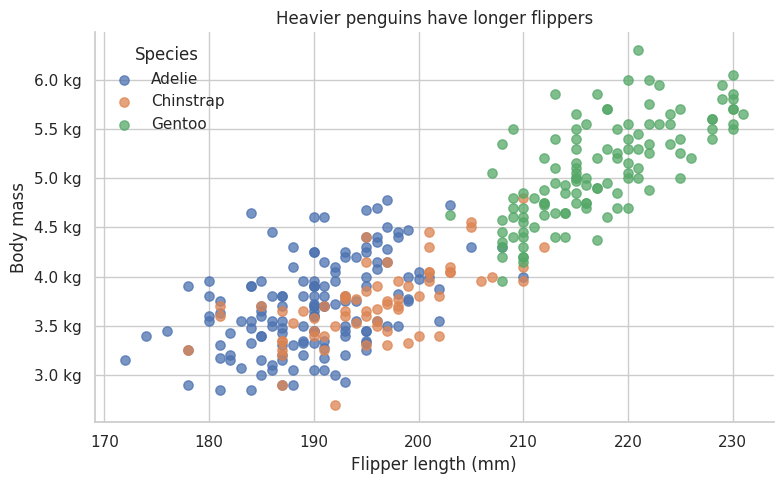

In [20]:
from matplotlib.ticker import FuncFormatter

penguins = sns.load_dataset("penguins").dropna()
fig, ax = plt.subplots(figsize=(8, 5))

for species, g in penguins.groupby("species", observed=True):
    ax.scatter(g["flipper_length_mm"], g["body_mass_g"], label=species, alpha=0.75, s=45)

ax.set(title="Heavier penguins have longer flippers",
       xlabel="Flipper length (mm)", ylabel="Body mass")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.1f} kg"))
ax.legend(title="Species", frameon=False)

fig.tight_layout()
fig.savefig("penguin_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Distributions: histograms + KDE
A lumpy overall shape often hides a categorical variable. Try different `bins`.

Skewness of body mass: 0.47


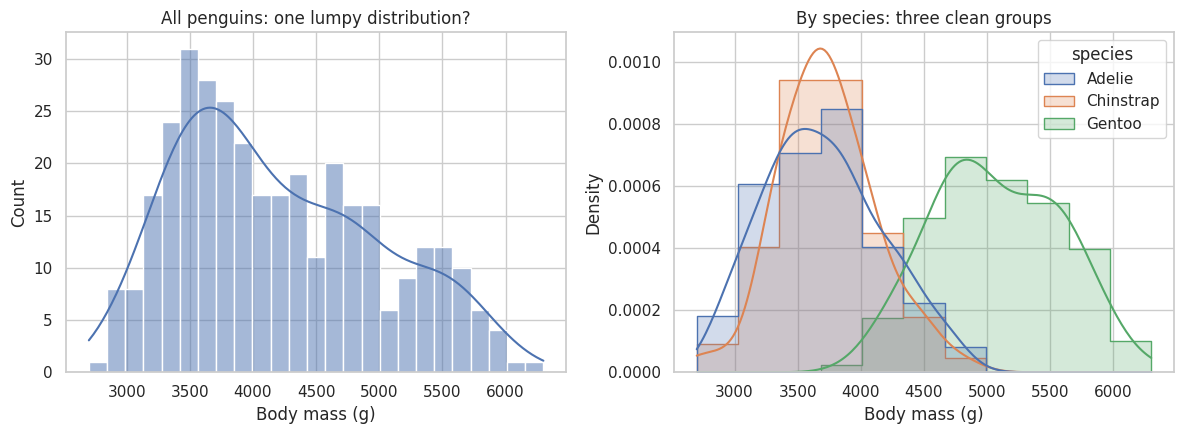

In [21]:
penguins = sns.load_dataset("penguins")
print("Skewness of body mass:", round(penguins["body_mass_g"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(data=penguins, x="body_mass_g", bins=25, kde=True, ax=axes[0])
axes[0].set_title("All penguins: one lumpy distribution?")

sns.histplot(data=penguins, x="body_mass_g", hue="species", kde=True,
             element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("By species: three clean groups")

for ax in axes:
    ax.set_xlabel("Body mass (g)")
plt.tight_layout(); plt.show()

## 8. Outlier hunting: box & violin plots
Flagging is not deleting: investigate first, and compute outliers *within groups*.

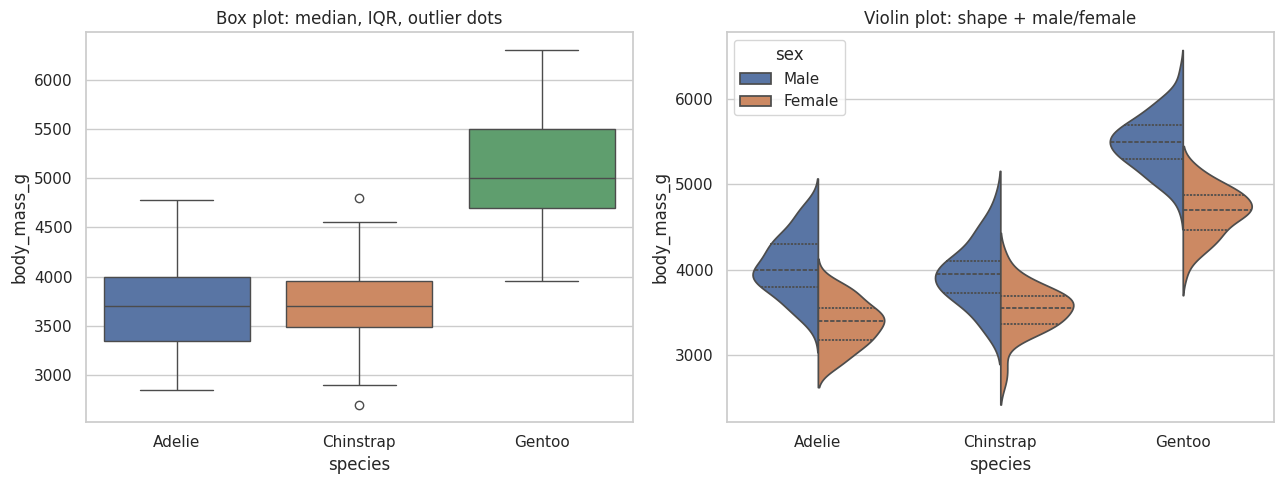

Flagged rows: 2
       species island     sex  body_mass_g
189  Chinstrap  Dream    Male       4800.0
190  Chinstrap  Dream  Female       2700.0


In [22]:
penguins = sns.load_dataset("penguins")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=penguins, x="species", y="body_mass_g", hue="species", legend=False, ax=axes[0])
axes[0].set_title("Box plot: median, IQR, outlier dots")
sns.violinplot(data=penguins, x="species", y="body_mass_g", hue="sex",
               split=True, inner="quartile", ax=axes[1])
axes[1].set_title("Violin plot: shape + male/female")
plt.tight_layout(); plt.show()

def iqr_outliers(s, k=1.5):
    """True where a value lies outside the k*IQR fences."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

penguins["is_outlier"] = penguins.groupby("species", observed=True)["body_mass_g"].transform(iqr_outliers)
print("Flagged rows:", int(penguins["is_outlier"].sum()))
print(penguins.loc[penguins["is_outlier"], ["species", "island", "sex", "body_mass_g"]])

## 9. Correlation analysis & heatmaps
Diverging colormap centered at 0 with `vmin=-1, vmax=1`; mask the redundant triangle. Note bill depth vs. bill length is slightly *negative*: hold that thought.

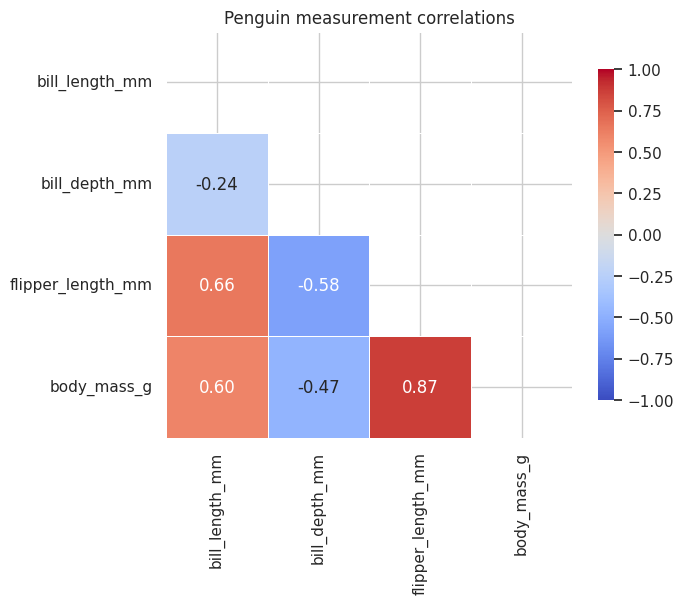

In [23]:
penguins = sns.load_dataset("penguins")
corr = penguins.select_dtypes("number").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Penguin measurement correlations")
plt.tight_layout(); plt.show()

## 10. Multi-variable scatter & Simpson's paradox
The pooled trend slopes down, but every species slopes *up*.

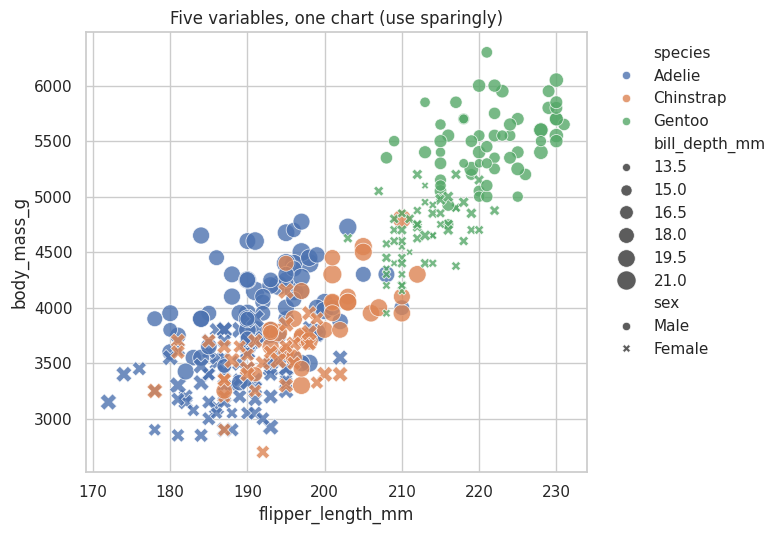

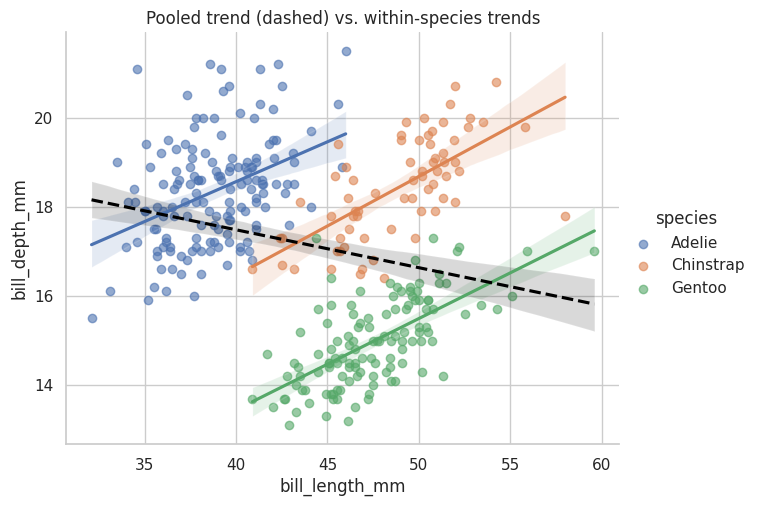

species
Adelie       0.39
Chinstrap    0.65
Gentoo       0.64
Name: bill_length_mm, dtype: float64


In [24]:
penguins = sns.load_dataset("penguins")

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="sex", size="bill_depth_mm", sizes=(25, 200),
                alpha=0.8, ax=ax)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax.set_title("Five variables, one chart (use sparingly)")
plt.tight_layout(); plt.show()

g = sns.lmplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", hue="species",
               height=5, aspect=1.3, scatter_kws={"alpha": 0.6})
sns.regplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", scatter=False,
            color="black", line_kws={"ls": "--"}, ax=g.ax)        # pooled line
g.ax.set_title("Pooled trend (dashed) vs. within-species trends")
plt.show()

print(penguins.groupby("species", observed=True)[["bill_length_mm", "bill_depth_mm"]]
      .corr().xs("bill_depth_mm", level=1)["bill_length_mm"].round(2))

## 11. Multi-panel dashboard & consistent style
One palette dictionary reused in every panel; axes-level Seaborn functions with `ax=axes[r, c]`.

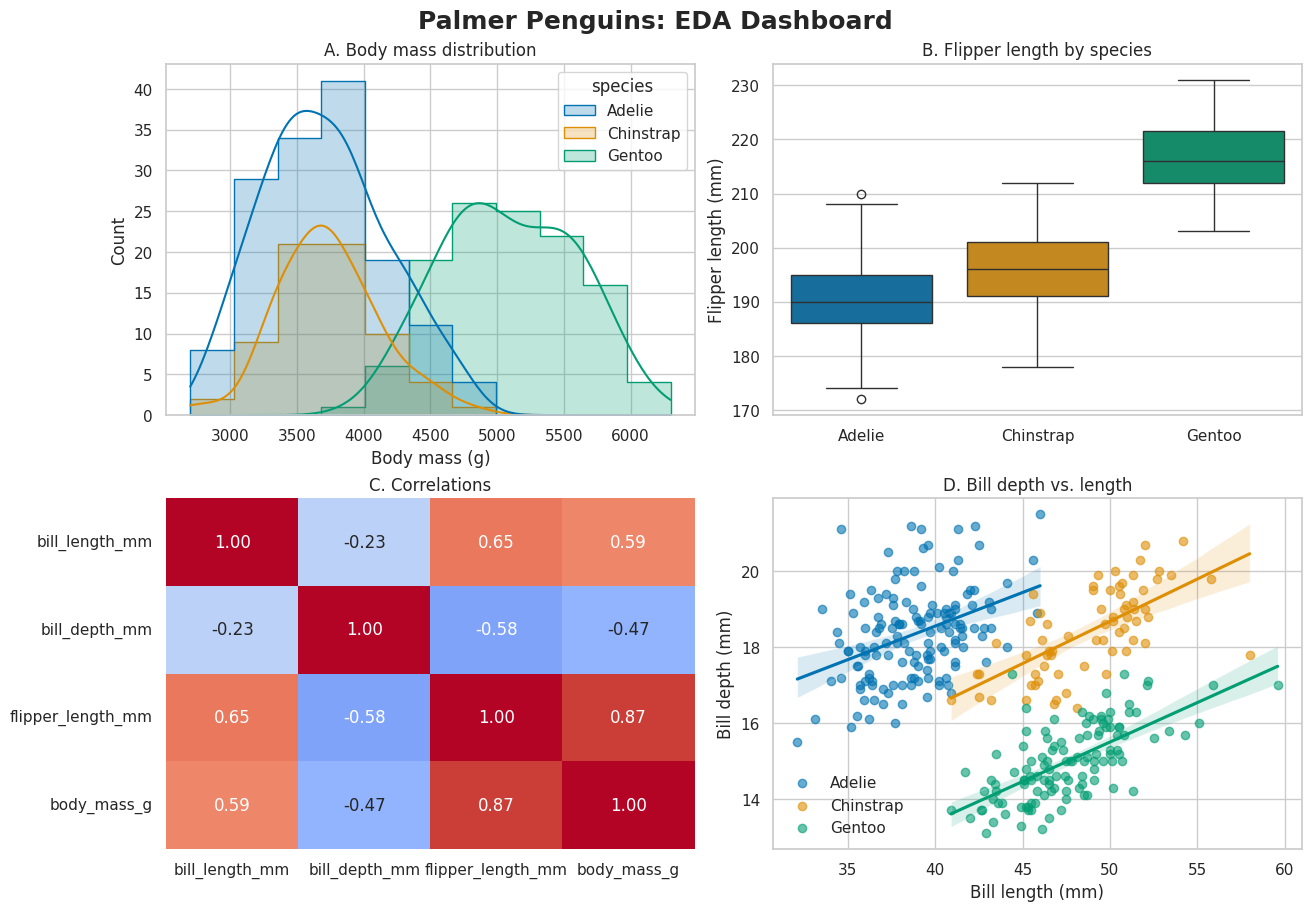

In [25]:
sns.set_theme(style="whitegrid", context="notebook")
penguins = sns.load_dataset("penguins").dropna()

species = ["Adelie", "Chinstrap", "Gentoo"]
palette = dict(zip(species, sns.color_palette("colorblind", 3)))

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")

sns.histplot(data=penguins, x="body_mass_g", hue="species", palette=palette,
             element="step", kde=True, ax=axes[0, 0])
axes[0, 0].set(title="A. Body mass distribution", xlabel="Body mass (g)")

sns.boxplot(data=penguins, x="species", y="flipper_length_mm", hue="species",
            palette=palette, legend=False, ax=axes[0, 1])
axes[0, 1].set(title="B. Flipper length by species", xlabel="", ylabel="Flipper length (mm)")

sns.heatmap(penguins.select_dtypes("number").corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar=False, ax=axes[1, 0])
axes[1, 0].set_title("C. Correlations")

for sp, g in penguins.groupby("species"):
    sns.regplot(data=g, x="bill_length_mm", y="bill_depth_mm", color=palette[sp],
                scatter_kws={"alpha": 0.6}, label=sp, ax=axes[1, 1])
axes[1, 1].set(title="D. Bill depth vs. length", xlabel="Bill length (mm)", ylabel="Bill depth (mm)")
axes[1, 1].legend(frameon=False)

fig.suptitle("Palmer Penguins: EDA Dashboard", fontsize=18, weight="bold")
fig.savefig("penguin_dashboard.png", dpi=300)
plt.show()

## 12. Capstone: Tips mini-project (10 min, in pairs)
**Q1:** Which (day, time) has the highest mean tip %, and is the sample big enough to trust it?
**Q2:** Does party size or smoking section change tip %? Show it in one figure.

Fill in every `___`, then write a one-sentence conclusion per question as comments. Look at the `n` column before celebrating any average.

              n  mean_tip_pct
day  time                    
Fri  Lunch    7         18.88
Sun  Dinner  76         16.69
Thur Lunch   61         16.13
     Dinner   1         15.97
Fri  Dinner  12         15.89
Sat  Dinner  87         15.32


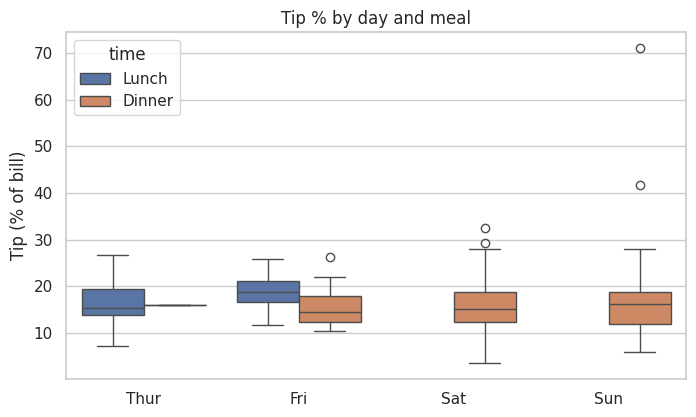

         size  tip_pct
size     1.00    -0.14
tip_pct -0.14     1.00


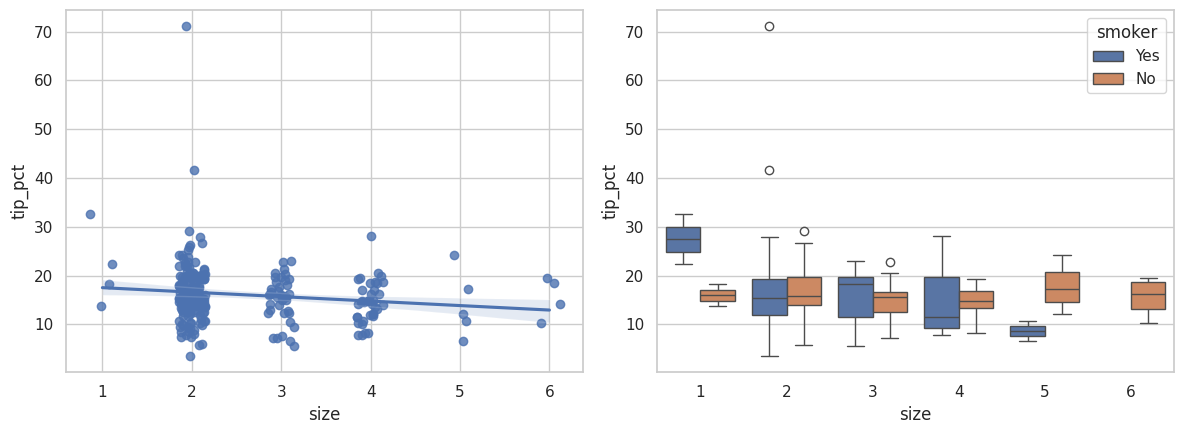

In [27]:
tips = sns.load_dataset("tips")
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100

q1 = (tips.groupby(["day", "time"], observed=True)["tip_pct"]
          .agg(n="count", mean_tip_pct="mean").round(2)
          .sort_values("mean_tip_pct", ascending=False))
print(q1)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=tips, x="day", y="tip_pct", hue="time", ax=ax)
ax.set(title="Tip % by day and meal", xlabel="", ylabel="Tip (% of bill)")
plt.show()

print(tips[["size", "tip_pct"]].corr().round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.regplot(data=tips, x="size", y="tip_pct", x_jitter=0.15, ax=axes[0])
sns.boxplot(data=tips, x="size", y="tip_pct", hue="smoker", ax=axes[1])
plt.tight_layout(); plt.show()

## 13. Pitfalls demo: truncated axes
Bar lengths encode value, so bar axes must start at zero.

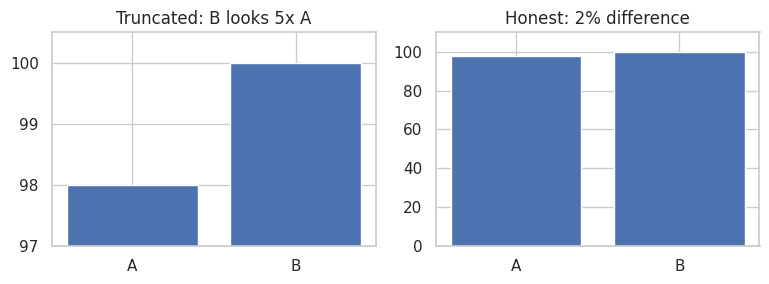

In [28]:
values, labels = [98, 100], ["A", "B"]
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(labels, values); axes[0].set_ylim(97, 100.5); axes[0].set_title("Truncated: B looks 5x A")
axes[1].bar(labels, values); axes[1].set_ylim(0, 110);    axes[1].set_title("Honest: 2% difference")
plt.tight_layout(); plt.show()

## Cheatsheet & next steps
| Task | Call |
|---|---|
| Schema / types | `df.info()`, `df.dtypes` |
| Missing values | `df.isna().sum()`, `dropna`, `fillna` |
| Summaries | `df.describe()`, `groupby().agg(name=(col, func))` |
| Reshape | `pivot_table`, `melt` |
| Figure & axes | `fig, ax = plt.subplots()`; `ax.set(...)`; `fig.savefig(dpi=300)` |
| Seaborn | `histplot(kde=True)`, `boxplot`, `violinplot`, `heatmap`, `scatterplot`, `regplot`, `lmplot` |
| Dashboards | `plt.subplots(r, c)` + `ax=axes[i, j]` |

**Pitfalls:** truncated bar axes · silent NaNs · pyplot state vs. OO axes · overplotting · unlabeled units · correlation ≠ causation.

**Resources:** pandas *10 Minutes to pandas* · seaborn tutorial · Matplotlib Quick Start · VanderPlas *Python Data Science Handbook* · Wilke *Fundamentals of Data Visualization* · python-graph-gallery.com · `mwaskom/seaborn-data`.

**Challenge:** deliver a one-page 2×2 dashboard (saved at `dpi=300`) on a new dataset (`titanic`, `diamonds`, or a Kaggle CSV) with a NaN audit, a distribution, a group comparison, a correlation view, and a title stating your main finding. Bonus: find a Simpson's-paradox reversal.